In [1]:
import numpy as np
import pandas as pd

In [3]:
df=pd.read_csv('Formspring.csv')
df.head()

,text,answer
0,Q: what&#039;s your favorite song? :D<br>A: I ...,No
1,Q: <3<br>A: </3 ? haha jk! <33,No
2,Q: &quot;hey angel you duh sexy&quot;<br>A: R...,No
3,Q: (:<br>A: ;(,No
4,Q: ******************MEOWWW*******************...,No


In [4]:
df.shape

(13147, 2)

In [6]:
df.describe()

,text,answer
count,13147,13147
unique,13144,2
top,Q: Wait. Are you Cheyenne? I sent a request to...,No
freq,3,12295


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13147 entries, 0 to 13146
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    13147 non-null  object
 1   answer  13147 non-null  object
dtypes: object(2)
memory usage: 205.6+ KB


In [9]:
df.isnull().sum()

text      0
answer    0
dtype: int64

answer
No     12295
Yes      852
Name: count, dtype: int64


<BarContainer object of 2 artists>

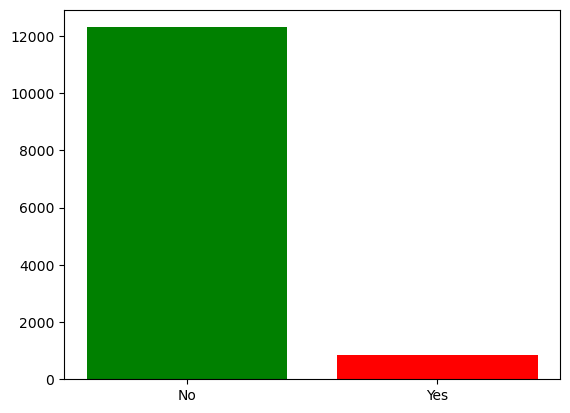

In [15]:
import matplotlib.pyplot as plt

count=df['answer'].value_counts()
print(count)
plt.bar(['No','Yes'],count.values,color=["green","red"])
plt.set_title(

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer=TfidfVectorizer()
text_features=df['text'].copy()
print(text_features)
features=vectorizer.fit_transform(text_features)
features

0        Q: what&#039;s your favorite song? :D<br>A: I ...
1                           Q: <3<br>A: </3 ? haha jk! <33
2        Q: &quot;hey angel  you duh sexy&quot;<br>A: R...
3                                           Q: (:<br>A: ;(
4        Q: ******************MEOWWW*******************...
                               ...                        
13142    Q: Youre at a party and your friend who drove ...
13143    Q: Youu2019re awesome :] Give yourself a compl...
13144    Q: Yu play with yurself ?<br>A: all the time. ...
13145    Q: yukk beer is disgusting. i can only drink i...
13146    Q: if i told u den it would make it all the le...
Name: text, Length: 13147, dtype: object


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 254506 stored elements and shape (13147, 18775)>

In [18]:
print(features)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 254506 stored elements and shape (13147, 18775)>
  Coords	Values
  (0, 17947)	0.15984947496542218
  (0, 4)	0.21166783975854714
  (0, 18614)	0.16445580974678042
  (0, 6020)	0.5901629635353193
  (0, 15130)	0.3373860496444202
  (0, 2417)	0.06294444269439241
  (0, 9775)	0.19038717708585326
  (0, 16688)	0.26377533756496274
  (0, 10321)	0.30068023170403524
  (0, 15135)	0.43794630875263
  (0, 16619)	0.13666204960704684
  (0, 7574)	0.17265193864975523
  (1, 2417)	0.10517467075209345
  (1, 7324)	0.3741534117644445
  (1, 8965)	0.6831137869399059
  (1, 212)	0.6183066126040023
  (2, 2417)	0.05634780356239197
  (2, 7324)	0.20045437554062448
  (2, 13327)	0.5094343603709673
  (2, 7765)	0.2886547397744486
  (2, 1044)	0.4381590967996309
  (2, 18600)	0.0865259371250384
  (2, 5157)	0.42483910836891375
  (2, 14472)	0.3371973861965128
  (2, 13501)	0.2132496484348259
  :	:
  (13145, 5128)	0.22992749038686963
  (13145, 4804)	0.3182924140169115
  (

In [19]:
pd.DataFrame(text_features).to_csv('text features.csv')

In [24]:
from sklearn.preprocessing import LabelEncoder

encoder=LabelEncoder()
# df['answer'].apply(encoder.fit_transform)
df['answer']=encoder.fit_transform(df['answer'])
df.head()

,text,answer
0,Q: what&#039;s your favorite song? :D<br>A: I ...,0
1,Q: <3<br>A: </3 ? haha jk! <33,0
2,Q: &quot;hey angel you duh sexy&quot;<br>A: R...,0
3,Q: (:<br>A: ;(,0
4,Q: ******************MEOWWW*******************...,0


In [25]:
df.dtypes

text      object
answer     int64
dtype: object

In [27]:
x=features
y=df['answer']

In [28]:
from sklearn.model_selection import train_test_split

xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=.2)

In [29]:
from sklearn.model_selection import GridSearchCV

from sklearn.svm import (SVR, SVC)
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import (Ridge, RidgeClassifier, SGDRegressor, SGDClassifier, LogisticRegression)
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix, 
    classification_report
)   

from matplotlib import style
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

In [31]:
# ----------------------------- Metric Scores: C-Support Vector Classification ----------------------------- #
svc = SVC(kernel="sigmoid", gamma=1.0)

svc.fit(xtrain, ytrain)

svc_pred = svc.predict(xtest)
svc_accuracy_score = accuracy_score(ytest, svc_pred)
svc_precision_score = precision_score(ytest, svc_pred)
svc_recall_score = recall_score(ytest, svc_pred)
svc_f1_score = f1_score(ytest, svc_pred)
# ---------------------------------------------------------------------------------------------------------- #
# -------------------------------------- Metric Scores: MultinomialNB -------------------------------------- #
mnb = MultinomialNB(alpha=0.2)

mnb.fit(xtrain, ytrain)

mnb_pred = mnb.predict(xtest)
mnb_accuracy_score = accuracy_score(ytest, mnb_pred)
mnb_precision_score = precision_score(ytest, mnb_pred)
mnb_recall_score = recall_score(ytest, mnb_pred)
mnb_f1_score = f1_score(ytest, mnb_pred)
# ---------------------------------------------------------------------------------------------------------- #
# --------------------------------- Metric Scores: DecisionTreeClassifier ---------------------------------- #
dtc = DecisionTreeClassifier()

dtc.fit(xtrain, ytrain)

dtc_pred = dtc.predict(xtest)
dtc_accuracy_score = accuracy_score(ytest, dtc_pred)
dtc_precision_score = precision_score(ytest, dtc_pred)
dtc_recall_score = recall_score(ytest, dtc_pred)
dtc_f1_score = f1_score(ytest, dtc_pred)
# ---------------------------------------------------------------------------------------------------------- #
print(f"""________Evaluation for: C-Support Vector Classification________
Model Type:         {svc}
Accuracy Score:     {svc_accuracy_score:%}
Precision Score:    {svc_precision_score:%}
Recall Score:       {svc_recall_score:%}
F1-Score:           {svc_f1_score:%}

C-Support Vector Classification - Confusion Matrix:
{confusion_matrix(ytest, svc_pred)}

C-Support Vector Classification - Classification Report:
{classification_report(ytest, svc_pred)}
----------------------------THE END----------------------------
______Evaluation for: Multinomial Naive Bayes Classifier_______
Model Type:         {mnb}
Accuracy Score:     {mnb_accuracy_score:%}
Precision Score:    {mnb_precision_score:%}
Recall Score:       {mnb_recall_score:%}
F1-Score:           {mnb_f1_score:%}

C-Support Vector Classification - Confusion Matrix:
{confusion_matrix(ytest, mnb_pred)}

C-Support Vector Classification - Classification Report:
{classification_report(ytest, mnb_pred)}
----------------------------THE END----------------------------
___________Evaluation for: Decision Tree Classifier____________
Model Type:         {dtc}
Accuracy Score:     {dtc_accuracy_score:%}
Precision Score:    {dtc_precision_score:%}
Recall Score:       {dtc_recall_score:%}
F1-Score:           {dtc_f1_score:%}

C-Support Vector Classification - Confusion Matrix:
{confusion_matrix(ytest, dtc_pred)}

C-Support Vector Classification - Classification Report:
{classification_report(ytest, dtc_pred)}
----------------------------THE END----------------------------""")
# ---------------------------------------------------------------------------------------------------------- #

________Evaluation for: C-Support Vector Classification________
Model Type:         SVC(gamma=1.0, kernel='sigmoid')
Accuracy Score:     95.133080%
Precision Score:    86.363636%
Recall Score:       32.386364%
F1-Score:           47.107438%

C-Support Vector Classification - Confusion Matrix:
[[2445    9]
 [ 119   57]]

C-Support Vector Classification - Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      2454
           1       0.86      0.32      0.47       176

    accuracy                           0.95      2630
   macro avg       0.91      0.66      0.72      2630
weighted avg       0.95      0.95      0.94      2630

----------------------------THE END----------------------------
______Evaluation for: Multinomial Naive Bayes Classifier_______
Model Type:         MultinomialNB(alpha=0.2)
Accuracy Score:     93.079848%
Precision Score:    44.642857%
Recall Score:       14.204545%
F1-Score:           21.55172